# 1. Business Understanding

### Business Problem
Imagine a content team at a streaming platform or a production company that has to decide
which kinds of anime are worth licensing, commissioning or promoting. Two signals matter to them: how well a title is
*rated* (`score`) and how strongly fans are *attached* to it (`favorites`). This project asks which kinds of anime
(type, genre, length, studio) tend to do well on those signals, and how much we can trust those patterns given the
quality of the data.

**Potential stakeholders**

- Content acquisition / licensing teams (what to buy or commission)
- Production studios and producers (what formats and genres to make)
- Marketing and community teams (which titles have loyal audiences)
- Analysts and fans who want to understand the catalogue

### Business Questions

1. **Audience attachment**: Which titles have the most favorites, and how concentrated is attachment in a small number of titles?
2. **Format and time**: Does the average score differ by anime type, and how has the number of titles released changed over time?
3. **Genre**: Which genres tend to have the highest average score, and how much does genre matter compared with differences between individual titles?
4. **Quality vs popularity**: Are the better-rated titles also the more popular ones, or is popularity a different thing from quality?
5. **What goes with higher scores**: Which studios, source materials and episode lengths are associated with higher scores?


# 2. Data Inspection

### 2.1 Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### 2.2 Loading and Previewing the Data

In [2]:
anime = pd.read_csv('data/top_anime_dataset.csv')

In [3]:
print("Rows:", anime.shape[0])
print("Columns:", anime.shape[1])

Rows: 15000
Columns: 17


In [4]:
# Preview the first rows
anime.head()

,anime_id,english_name,score,genres,synopsis,type,episodes,premiered,producers,studios,source,duration,Age_can_read,rank,popularity,favorites,scored_by
0,52991,Frieren: Beyond Journey's End,9.31,"Adventure, Drama, Fantasy",During their decade-long quest to defeat the D...,TV,28.0,fall 2023,"Aniplex, Dentsu, Shogakukan-Shueisha Productio...",Madhouse,Manga,24 min per ep,PG-13 - Teens 13 or older,1.0,160,63200,603520
1,5114,Fullmetal Alchemist: Brotherhood,9.10,"Action, Adventure, Drama, Fantasy",After a horrific alchemy experiment goes wrong...,TV,64.0,spring 2009,"Aniplex, Square Enix, Mainichi Broadcasting Sy...",Bones,Manga,24 min per ep,R - 17+ (violence & profanity),2.0,3,231928,2196353
2,9253,Steins;Gate,9.07,"Drama, Sci-Fi, Suspense",Eccentric scientist Rintarou Okabe has a never...,TV,24.0,spring 2011,"Frontier Works, Media Factory, Kadokawa Shoten...",White Fox,Visual novel,24 min per ep,PG-13 - Teens 13 or older,3.0,14,194507,1449844
3,60022,NaN,9.06,"Action, Adventure, Fantasy",Although the golden age of piracy is about to ...,TV Special,1.0,NaN,NaN,Toei Animation,Light novel,24 min,PG-13 - Teens 13 or older,4.0,2350,1970,68977
4,38524,Attack on Titan Season 3 Part 2,9.05,"Action, Drama, Suspense",Seeking to restore humanity's diminishing hope...,TV,10.0,spring 2019,"Production I.G, Dentsu, Mainichi Broadcasting ...",Wit Studio,Manga,23 min per ep,R - 17+ (violence & profanity),5.0,21,60500,1671010


In [5]:
anime.tail()

,anime_id,english_name,score,genres,synopsis,type,episodes,premiered,producers,studios,source,duration,Age_can_read,rank,popularity,favorites,scored_by
14995,1595,Beast City,5.57,Hentai,The modern age. Albeit tales of strange things...,OVA,3.0,NaN,"Comstock, Ltd.",C and R,Light novel,41 min per ep,Rx - Hentai,NaN,10513,9,883
14996,49943,NaN,5.57,Hentai,Aima Imoko is a young college student with a h...,OVA,4.0,NaN,NaN,Mousou Senka,Manga,20 min per ep,Rx - Hentai,NaN,9348,8,1675
14997,38812,NaN,5.57,NaN,A short music video of the song Botsuraku by t...,Music,1.0,NaN,Victor Entertainment,NaN,Original,1 min,G - All Ages,NaN,18697,0,196
14998,38914,Papa's March,5.57,NaN,Official music video directed by Mitsuyuki Ish...,Music,1.0,NaN,NaN,NaN,Original,3 min,G - All Ages,NaN,20187,0,132
14999,21715,NaN,5.57,NaN,"When the last ray of the sun disappears, the d...",Music,1.0,NaN,NHK,NaN,Original,2 min,G - All Ages,NaN,17247,1,245


In [6]:
anime.describe()

,anime_id,score,episodes,rank,popularity,favorites,scored_by
count,15000.000000,15000.000000,14885.000000,11921.000000,15000.000000,15000.000000,1.500000e+04
mean,25735.652533,6.673484,12.662009,5947.337723,8485.094133,803.284667,3.586614e+04
std,19322.104925,0.703748,50.303656,3434.518105,5475.365792,6103.432034,1.321266e+05
min,1.000000,5.570000,1.000000,1.000000,1.000000,0.000000,1.020000e+02
25%,5852.750000,6.110000,1.000000,2975.000000,3854.750000,2.000000,5.267500e+02
50%,27827.000000,6.580000,2.000000,5944.000000,7913.500000,11.000000,2.490500e+03
75%,40835.250000,7.170000,12.000000,8918.000000,12575.250000,92.250000,1.529800e+04
max,60988.000000,9.310000,3057.000000,11923.000000,21856.000000,234344.000000,2.904954e+06


In [7]:
anime.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   anime_id      15000 non-null  int64  
 1   english_name  8355 non-null   object 
 2   score         15000 non-null  float64
 3   genres        13397 non-null  object 
 4   synopsis      14527 non-null  object 
 5   type          14999 non-null  object 
 6   episodes      14885 non-null  float64
 7   premiered     4686 non-null   object 
 8   producers     9568 non-null   object 
 9   studios       12617 non-null  object 
 10  source        15000 non-null  object 
 11  duration      15000 non-null  object 
 12  Age_can_read  14932 non-null  object 
 13  rank          11921 non-null  float64
 14  popularity    15000 non-null  int64  
 15  favorites     15000 non-null  int64  
 16  scored_by     15000 non-null  int64  
dtypes: float64(3), int64(4), object(10)
memory usage: 1.9+ MB


In [8]:
numeric_vars = anime.select_dtypes(include='number').columns.tolist()
categorical_vars = anime.select_dtypes(exclude='number').columns.tolist()
print("Numerical:", numeric_vars)
print()
print("Categorical / text:", categorical_vars)

Numerical: ['anime_id', 'score', 'episodes', 'rank', 'popularity', 'favorites', 'scored_by']

Categorical / text: ['english_name', 'genres', 'synopsis', 'type', 'premiered', 'producers', 'studios', 'source', 'duration', 'Age_can_read']


**Finding:** the raw file has 15,000 rows and 17 columns. Only six columns are really numerical (`anime_id` is just an
identifier). The numbers are very uneven: the average title has 803 favorites but the median title only has 11, and the
average `scored_by` is about 35,900 while the median is about 2,500. A few very popular titles pull the means far above
the typical title, so from here on I rely on **medians, rank correlations and log scales** instead of plain averages.

# 3. Data Quality Assessment

### 3.1 Missing Values and Cardinality

In [9]:
anime.isnull().sum()

anime_id            0
english_name     6645
score               0
genres           1603
synopsis          473
type                1
episodes          115
premiered       10314
producers        5432
studios          2383
source              0
duration            0
Age_can_read       68
rank             3079
popularity          0
favorites           0
scored_by           0
dtype: int64

In [10]:
# Same counts as percentages, easier to compare across columns
(anime.isnull().mean() * 100).round(1).sort_values(ascending=False)

premiered       68.8
english_name    44.3
producers       36.2
rank            20.5
studios         15.9
genres          10.7
synopsis         3.2
episodes         0.8
Age_can_read     0.5
anime_id         0.0
score            0.0
type             0.0
source           0.0
duration         0.0
popularity       0.0
favorites        0.0
scored_by        0.0
dtype: float64

In [11]:
anime.nunique()

anime_id        14965
english_name     8214
score             344
genres            865
synopsis        14368
type                9
episodes          198
premiered         240
producers        4451
studios          1421
source             17
duration          311
Age_can_read        6
rank             9597
popularity      13501
favorites        1926
scored_by        8782
dtype: int64

In [12]:
# Is the missing data random, or does it depend on the anime type?
missing_by_type = pd.DataFrame({
    'titles': anime.groupby('type').size(),
    'premiered_filled_%': anime.groupby('type')['premiered'].apply(lambda s: s.notna().mean() * 100).round(1),
    'rank_filled_%': anime.groupby('type')['rank'].apply(lambda s: s.notna().mean() * 100).round(1),
})
missing_by_type

,titles,premiered_filled_%,rank_filled_%
type,,,
CM,206,0.0,0.0
Movie,2086,0.0,99.7
Music,1486,0.0,0.0
ONA,1790,0.0,96.4
OVA,2780,0.0,58.5
PV,130,0.0,0.0
Special,1297,0.0,98.0
TV,4718,99.3,99.9
TV Special,506,0.0,100.0


**Finding:** several columns have substantial missing data that should be kept in mind
throughout the analysis:

- `premiered` (the season/year a title first aired) is missing for **10,314 of 15,000 rows
  (~69%)**. The table above shows this is not random: see the finding below the table.
- `english_name` is missing for ~44% of titles, `rank` for ~21%, and `producers` for ~36%. These
  do not affect the analyses below directly (which rely on `favorites`, `score`, `type`, and
  `genres`), but would need attention for any analysis that depends on them.
- Core numeric fields used in this notebook - `score`, `favorites`, `popularity`, `scored_by` -
  have no missing values.

The missing `premiered` values are **structural, not random**. 99% of TV series have a `premiered` value
and none of the other types (Movie, OVA, ONA, Special, Music, CM, PV, TV Special) have one. In the same way `rank` is
empty for every Music, CM and PV title and for about 40% of OVAs. So I do not treat these gaps as errors to repair.
They tell me that **any analysis by release year can only describe TV series**, and I keep the blanks as they are.

### 3.2 Duplicate Records

In [13]:
anime.duplicated().sum()

np.int64(35)

In [14]:
# Are the duplicates exact copies? If so, the number of repeated anime_id values should match
print("Repeated anime_id values:", anime['anime_id'].duplicated().sum())
anime[anime.duplicated(keep=False)].sort_values('anime_id')[['anime_id', 'english_name', 'score', 'type', 'favorites']].head(6)

Repeated anime_id values: 35


,anime_id,english_name,score,type,favorites
10526,50385,NaN,6.20,Special,0
10527,50385,NaN,6.20,Special,0
8821,56207,NaN,6.41,ONA,12
8820,56207,NaN,6.41,ONA,12
13909,58873,NaN,5.73,ONA,5
13910,58873,NaN,5.73,ONA,5


**Finding:** 35 rows are exact copies of another row (the 35 repeated `anime_id` values match the 35 duplicate rows, and
the pairs have identical scores and favorites), which leaves 14,965 unique titles.

### 3.3 Data Types, Inconsistent Values and Data Integrity

In [15]:
print(anime['type'].value_counts(dropna=False), "\n")
print(anime['Age_can_read'].value_counts(dropna=False), "\n")
print(anime['source'].value_counts())

type
TV            4718
OVA           2780
Movie         2086
ONA           1790
Music         1486
Special       1297
TV Special     506
CM             206
PV             130
NaN              1
Name: count, dtype: int64 

Age_can_read
PG-13 - Teens 13 or older         7525
G - All Ages                      3113
R - 17+ (violence & profanity)    1305
Rx - Hentai                       1208
PG - Children                      938
R+ - Mild Nudity                   843
NaN                                 68
Name: count, dtype: int64 

source
Manga           4500
Original        4238
Game            1018
Light novel     1012
Visual novel     977
Unknown          858
Novel            583
Other            509
Web manga        403
4-koma manga     281
Mixed media      176
Web novel        126
Music             93
Book              93
Card game         66
Picture book      64
Radio              3
Name: count, dtype: int64


In [16]:
text_cols = ['english_name', 'genres', 'type', 'source', 'studios', 'Age_can_read', 'premiered', 'duration']
whitespace_problems = sum((anime[c].dropna() != anime[c].dropna().str.strip()).sum() for c in text_cols)

print("Score range:", anime['score'].min(), "to", anime['score'].max())
print("Negative values in favorites / scored_by / popularity:", (anime[['favorites', 'scored_by', 'popularity']] < 0).sum().sum())
print("Rows where favorites > scored_by:", (anime['favorites'] > anime['scored_by']).sum())
print("Rows with fewer than 1 episode:", (anime['episodes'] < 1).sum())
print("Text values with leading/trailing spaces:", whitespace_problems)
print()
anime['duration'].value_counts().head(8)

Score range: 5.57 to 9.31
Negative values in favorites / scored_by / popularity: 0
Rows where favorites > scored_by: 0
Rows with fewer than 1 episode: 0
Text values with leading/trailing spaces: 0



duration
24 min per ep    1929
23 min per ep    1641
25 min per ep     692
3 min             676
4 min             530
2 min             385
3 min per ep      294
23 min            291
Name: count, dtype: int64

**Finding:** the data is consistent. There are no stray spaces, no negative counts, scores stay between 5.57 and 9.31,
and `favorites` never exceeds `scored_by`. The only real issues are one missing `type`, 68 missing `Age_can_read`
values, and `duration` stored as text (for example "24 min per ep"). `source` already has an "Unknown" category (858
titles), which I keep as a real label. `TV Special` and `Special` are different values in the data, so I keep them
separate.

### 3.4 Distribution Overview and Outliers

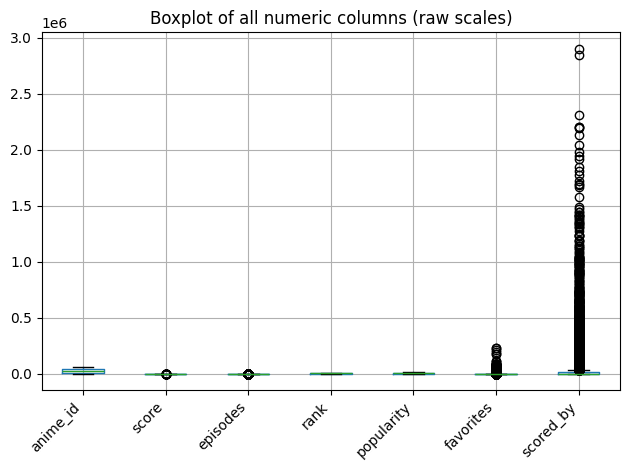

In [17]:
anime.boxplot()
plt.title('Boxplot of all numeric columns (raw scales)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [18]:
numeric_cols = anime.select_dtypes(include=['int64', 'float64']).columns

outlier_counts = {}
for col in numeric_cols:
    Q1 = anime[col].quantile(0.25)
    Q3 = anime[col].quantile(0.75)
    IQR = Q3 - Q1
    is_outlier = (anime[col] < Q1 - 1.5 * IQR) | (anime[col] > Q3 + 1.5 * IQR)
    outlier_counts[col] = is_outlier.sum()

pd.Series(outlier_counts, name='outlier_count')

anime_id         0
score           40
episodes      1270
rank             0
popularity       0
favorites     2590
scored_by     2378
Name: outlier_count, dtype: int64

**Finding:** `favorites` (2,590 outliers) and `scored_by` (2,378 outliers) have the most
IQR-flagged outliers, which is expected — a small number of extremely popular titles receive far
more favorites and ratings than the typical anime, producing a long right tail. `episodes` also
has a large outlier count (1,270), consistent with most titles having a short, standard episode
count and a minority (long-running series) extending far beyond it.

The IQR rule flags a lot of rows: 2,590 for `favorites` (about 17% of titles), 2,378 for `scored_by`
(about 16%) and 1,270 for `episodes`. These are not data-entry errors. They are the genuinely popular titles and the
long-running series. I keep all of them, because removing them would
delete the most successful titles from an analysis about success. Instead I use medians, Spearman (rank) correlation
and log scales.

# 4. Data Cleaning and Preparation

### 4.1 Remove Duplicate Records

In [19]:
# Remove duplicate rows
print("Before:", len(anime))
anime = anime.drop_duplicates()
print("After:", len(anime))

Before: 15000
After: 14965


### 4.2 Handle Missing Values

In [20]:
# Category labels: fill blanks with 'Unknown'
for col in ['type', 'Age_can_read', 'genres', 'studios', 'producers']:
    anime[col] = anime[col].fillna('Unknown')

# Readable label for charts: English name if we have it, otherwise the ID
anime['title'] = anime['english_name'].fillna('Anime ID ' + anime['anime_id'].astype(str))

anime[['type', 'Age_can_read', 'genres', 'studios', 'producers']].eq('Unknown').sum()

type               1
Age_can_read      68
genres          1596
studios         2374
producers       5410
dtype: int64

### 4.3 Standardize Categorical Values and Clean the Genre Column

In [21]:
# Strip stray spaces from every text column
for col in ['genres', 'type', 'source', 'studios', 'Age_can_read']:
    anime[col] = anime[col].str.strip()

# 'genres' holds several labels in one cell, e.g. "Action, Adventure, Drama".
# Split them into one row per (anime, genre) so every genre can be analysed on its own
genre_bridge = anime.loc[anime['genres'] != 'Unknown', ['anime_id', 'genres']].copy()
genre_bridge['genres'] = genre_bridge['genres'].str.split(',')
genre_bridge = genre_bridge.explode('genres')
genre_bridge['genres'] = genre_bridge['genres'].str.strip()
genre_bridge = genre_bridge.rename(columns={'genres': 'genre'})

print("Distinct genres:", genre_bridge['genre'].nunique())
print(sorted(genre_bridge['genre'].unique()))
print("Rows in genre table:", len(genre_bridge))

Distinct genres: 21
['Action', 'Adventure', 'Avant Garde', 'Award Winning', 'Boys Love', 'Comedy', 'Drama', 'Ecchi', 'Erotica', 'Fantasy', 'Girls Love', 'Gourmet', 'Hentai', 'Horror', 'Mystery', 'Romance', 'Sci-Fi', 'Slice of Life', 'Sports', 'Supernatural', 'Suspense']
Rows in genre table: 28471


**Finding:** there are 21 distinct genres. 1,596 titles have no genre, and they are left out of every genre analysis.
The remaining 13,369 titles produce 28,471 title-genre rows, so a title has about 2 genres on average. This is a
many-to-many relationship, so a title counts once in each of its genres. Because of that, the genre counts in this
analysis add up to more than the number of titles.

### 4.4 Extract the Release Year and Season

In [22]:
# Same extraction as the original notebook, now stored as a number instead of text
anime['year'] = anime['premiered'].str.extract(r'(\d{4})')[0]
anime['year'] = pd.to_numeric(anime['year']).astype('Int64')

# The season is the first word of 'premiered' (winter / spring / summer / fall)
anime['season'] = anime['premiered'].str.extract(r'^(\w+)')[0].str.title()

print("Titles with a release year:", anime['year'].notna().sum())
print("Year range:", anime['year'].min(), "to", anime['year'].max())
anime['season'].value_counts()

Titles with a release year: 4681
Year range: 1961 to 2025


season
Spring    1491
Fall      1408
Winter     974
Summer     808
Name: count, dtype: int64

### 4.5 Correct Data Types

In [23]:
# episodes and rank are whole numbers, they were floats only because of the missing values
anime['episodes'] = anime['episodes'].astype('Int64')
anime['rank'] = anime['rank'].astype('Int64')

# duration is text like '24 min per ep', '1 hr 30 min' or '30 sec'. Convert it to minutes.
hours = pd.to_numeric(anime['duration'].str.extract(r'(\d+) hr')[0]).fillna(0)
minutes = pd.to_numeric(anime['duration'].str.extract(r'(\d+) min')[0]).fillna(0)
seconds = pd.to_numeric(anime['duration'].str.extract(r'(\d+) sec')[0]).fillna(0)
anime['duration_min'] = (hours * 60 + minutes + seconds / 60).round(2)
anime.loc[anime['duration'] == 'Unknown', 'duration_min'] = np.nan

anime[['duration', 'duration_min']].sample(6, random_state=1)

,duration,duration_min
2793,24 min per ep,24.0
863,23 min per ep,23.0
4282,23 min per ep,23.0
13383,5 min per ep,5.0
999,23 min per ep,23.0
4418,25 min per ep,25.0


### 4.6 Validate the Cleaned Dataset

In [24]:
assert anime.duplicated().sum() == 0, "duplicate rows remain"
assert anime['anime_id'].is_unique, "anime_id is not unique"
assert anime['score'].between(1, 10).all(), "score outside 1-10"
assert (anime[['favorites', 'scored_by']] >= 0).all().all(), "negative counts"
assert anime['year'].dropna().between(1900, 2026).all(), "implausible release year"
assert anime[['type', 'genres', 'studios', 'Age_can_read']].notna().all().all(), "blank category labels remain"

print("All validation checks passed")
print("Rows:", len(anime))
anime.isnull().sum()[lambda s: s > 0]

All validation checks passed
Rows: 14965


english_name     6627
synopsis          470
episodes          109
premiered       10284
rank             3066
year            10284
season          10284
duration_min       14
dtype: int64

**Finding:** all checks pass and 14,965 rows remain. The columns that still contain blanks are the ones I decided to
leave alone: `english_name` (6,627), `synopsis` (470), `episodes` (109), `rank` (3,066), `duration_min` (14), and
`premiered` / `year` / `season` (10,284, TV only).

# 5. Feature Engineering (for Power BI dashboard)

In [25]:
# Number of genres per title (0 when the genre is unknown)
anime['genre_count'] = anime['genres'].str.count(',') + 1
anime.loc[anime['genres'] == 'Unknown', 'genre_count'] = 0

# Main studio = first studio listed. About 8% of titles list more than one studio.
anime['main_studio'] = anime['studios'].str.split(',').str[0].str.strip()

# Episode category
ep_labels = ['Single episode', 'Short (2-13)', 'Medium (14-26)', 'Long (27-52)', 'Very long (53+)']
anime['episode_category'] = pd.cut(anime['episodes'].astype(float), bins=[0, 1, 13, 26, 52, np.inf], labels=ep_labels).astype(object)
anime['episode_category'] = anime['episode_category'].fillna('Unknown')

# Rating category from the score
score_labels = ['Below 6.0', '6.0-6.9', '7.0-7.9', '8.0 and above']
anime['score_category'] = pd.cut(anime['score'], bins=[0, 6, 7, 8, 10], labels=score_labels, right=False).astype(object)

# Popularity category from the popularity rank (1 = most popular)
pop_labels = ['Top 1,000', '1,001-5,000', '5,001-10,000', 'Above 10,000']
anime['popularity_category'] = pd.cut(anime['popularity'], bins=[0, 1000, 5000, 10000, np.inf], labels=pop_labels).astype(object)

# Sort-order helpers (so Power BI can sort these categories logically instead of alphabetically)
anime['episode_category_order'] = anime['episode_category'].map({l: i + 1 for i, l in enumerate(ep_labels + ['Unknown'])})
anime['score_category_order'] = anime['score_category'].map({l: i + 1 for i, l in enumerate(score_labels)})
anime['popularity_category_order'] = anime['popularity_category'].map({l: i + 1 for i, l in enumerate(pop_labels)})

# Engagement: favorites per 1,000 users who rated the title (fair comparison between big and small titles)
anime['favorites_per_1k_ratings'] = (anime['favorites'] / anime['scored_by'] * 1000).round(2)

anime[['title', 'genre_count', 'main_studio', 'episode_category', 'score_category', 'popularity_category', 'favorites_per_1k_ratings']].head()

,title,genre_count,main_studio,episode_category,score_category,popularity_category,favorites_per_1k_ratings
0,Frieren: Beyond Journey's End,3,Madhouse,Long (27-52),8.0 and above,"Top 1,000",104.72
1,Fullmetal Alchemist: Brotherhood,4,Bones,Very long (53+),8.0 and above,"Top 1,000",105.60
2,Steins;Gate,3,White Fox,Medium (14-26),8.0 and above,"Top 1,000",134.16
3,Anime ID 60022,3,Toei Animation,Single episode,8.0 and above,"1,001-5,000",28.56
4,Attack on Titan Season 3 Part 2,3,Wit Studio,Short (2-13),8.0 and above,"Top 1,000",36.21


**Finding:** the new categories are not balanced, and that matters for later charts. Only 686 titles (4.6%) score 8.0
or above, while 2,888 (19.3%) score below 6.0. There are 6,351 single-episode titles, the biggest group. The "Top 1,000" popularity tier has 994 titles rather than 1,000, because the popularity ranks come from the
whole catalogue and not every rank is in this file. `favorites_per_1k_ratings` has a median of 4.85 but a maximum of
702.86: tiny titles with a few raters can produce extreme values, so I use the median for this column.

In [26]:
print(anime['episode_category'].value_counts().reindex(ep_labels + ['Unknown']), "\n")
print(anime['score_category'].value_counts().reindex(score_labels), "\n")
print(anime['popularity_category'].value_counts().reindex(pop_labels))

episode_category
Single episode     6351
Short (2-13)       5795
Medium (14-26)     1409
Long (27-52)        920
Very long (53+)     381
Unknown             109
Name: count, dtype: int64 

score_category
Below 6.0        2888
6.0-6.9          7319
7.0-7.9          4072
8.0 and above     686
Name: count, dtype: int64 

popularity_category
Top 1,000        994
1,001-5,000     3818
5,001-10,000    4506
Above 10,000    5647
Name: count, dtype: int64


### Export the Cleaned Dataset

In [27]:
anime_cleaned = anime.drop(columns=['synopsis'])
anime_cleaned.to_csv('anime_cleaned.csv', index=False, encoding='utf-8')
genre_bridge.to_csv('anime_genres.csv', index=False, encoding='utf-8')

# Read the files back to prove the export worked
check = pd.read_csv('anime_cleaned.csv')
check_genres = pd.read_csv('anime_genres.csv')
print("anime_cleaned.csv :", check.shape[0], "rows x", check.shape[1], "columns")
print("anime_genres.csv  :", check_genres.shape[0], "rows x", check_genres.shape[1], "columns")
print("Same number of titles as the notebook:", len(check) == len(anime))
print()
print(list(check.columns))

anime_cleaned.csv : 14965 rows x 29 columns
anime_genres.csv  : 28471 rows x 2 columns
Same number of titles as the notebook: True

['anime_id', 'english_name', 'score', 'genres', 'type', 'episodes', 'premiered', 'producers', 'studios', 'source', 'duration', 'Age_can_read', 'rank', 'popularity', 'favorites', 'scored_by', 'title', 'year', 'season', 'duration_min', 'genre_count', 'main_studio', 'episode_category', 'score_category', 'popularity_category', 'episode_category_order', 'score_category_order', 'popularity_category_order', 'favorites_per_1k_ratings']


# 6. Exploratory Data Analysis

### 6.1 Top 10 Most-Favorited Anime

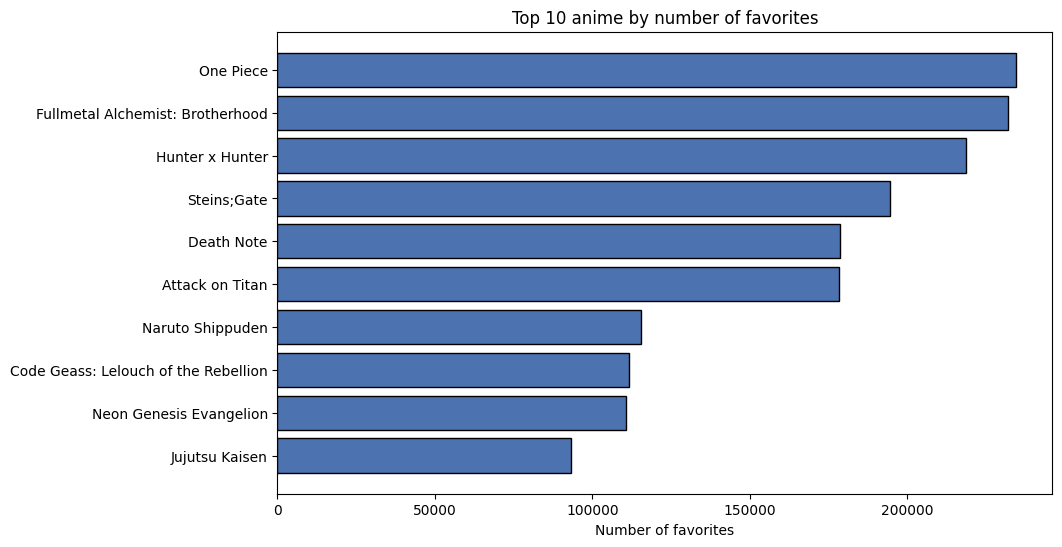

In [28]:
top10 = anime.nlargest(10, 'favorites')[['english_name', 'favorites']]

plt.figure(figsize=(10, 6))
plt.barh(top10['english_name'], top10['favorites'], color='#4C72B0', edgecolor='black')
plt.title("Top 10 anime by number of favorites")
plt.xlabel("Number of favorites")
plt.gca().invert_yaxis()
plt.show()

In [29]:
anime.nlargest(10, 'favorites')[['title', 'type', 'episodes', 'score', 'favorites']]

,title,type,episodes,score,favorites
55,One Piece,TV,<NA>,8.73,234344
1,Fullmetal Alchemist: Brotherhood,TV,64,9.10,231928
7,Hunter x Hunter,TV,148,9.03,218449
2,Steins;Gate,TV,24,9.07,194507
92,Death Note,TV,37,8.62,178500
116,Attack on Titan,TV,25,8.56,178145
313,Naruto Shippuden,TV,500,8.28,115525
64,Code Geass: Lelouch of the Rebellion,TV,25,8.70,111695
234,Neon Genesis Evangelion,TV,26,8.36,110742
118,Jujutsu Kaisen,TV,24,8.56,93177


**Finding:** all ten of the most-favorited titles are **TV series**, led by *One Piece* (234K favorites),
*Fullmetal Alchemist: Brotherhood* (232K) and *Hunter x Hunter* (218K). Their favorite counts range from about 93K to
234K. In the original version of this analysis I called them all "long-running", but the table shows that is not true.
Five of them have only 24-26 episodes (*Steins;Gate*, *Attack on Titan*, *Code Geass*, *Neon Genesis Evangelion*,
*Jujutsu Kaisen*), four have more than 30 (*Fullmetal Alchemist: Brotherhood*, *Hunter x Hunter*, *Death Note*, *Naruto
Shippuden*) and *One Piece* has no episode count in the data. So the TV format matters, but a very long run is not
required.

### 6.2 Average Score by Anime Type

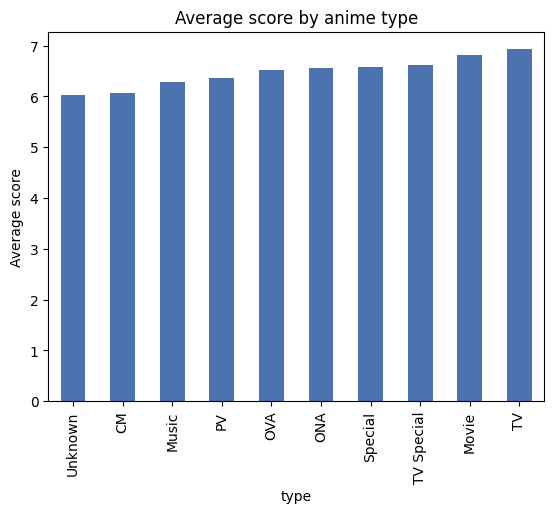

In [30]:
avg_score_type = anime.groupby('type')['score'].mean().sort_values(ascending=True)
avg_score_type.plot(kind='bar', title='Average score by anime type', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

In [31]:
# Average, median and number of titles for each type
anime.groupby('type')['score'].agg(['count', 'mean', 'median']).round(2).sort_values('mean', ascending=False)

,count,mean,median
type,,,
TV,4713,6.93,6.89
Movie,2084,6.82,6.77
TV Special,503,6.62,6.53
Special,1295,6.59,6.54
ONA,1779,6.55,6.45
OVA,2778,6.51,6.43
PV,128,6.37,6.28
Music,1478,6.29,6.22
CM,206,6.07,5.96


**Finding:** in this dataset, **TV** series have the highest average score (≈6.93),
followed closely by **Movie** (≈6.82); short-form types such as **CM** (≈6.07), **Music**
(≈6.29), and **PV** (≈6.37) score noticeably lower.

### 6.3 Number of Anime Released per Year (TV series)

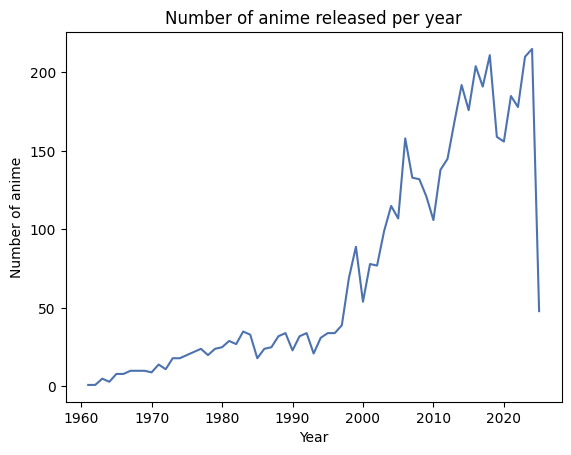

In [32]:
# Count titles per year:
year_count = anime['year'].value_counts().sort_index()
year_count.plot(kind='line', title='Number of anime released per year', color='#4C72B0')
plt.xlabel('Year')
plt.ylabel("Number of anime")
plt.show()

In [33]:
# Titles per decade, then the most recent years
decade_count = year_count.groupby((year_count.index // 10) * 10).sum()
print(decade_count, "\n")
year_count.tail(8)

year
1960      56
1970     180
1980     282
1990     406
2000    1074
2010    1691
2020     992
Name: count, dtype: Int64 



year
2018    211
2019    159
2020    156
2021    185
2022    178
2023    210
2024    215
2025     48
Name: count, dtype: Int64

**Finding:** this chart only covers **TV series**, because `premiered` is empty for every other type. Among
the 4,681 TV titles with a known year, the number of titles grows in every decade: 56 in the 1960s, 180 in the 1970s,
282 in the 1980s and 406 in the 1990s, then jumps to 1,074 in the 2000s and 1,691 in the 2010s. Recent years sit around
160-215 titles per year (2018, 2023 and 2024 each have more than 210). 2025 has only 48 titles, which is a partial year
and not a real drop, and the 2020s total (992) is partial for the same reason.

**Caveat:** this describes TV series in a list of the top titles by score, not the total output of the industry.

### 6.4 Average Score by Genre (Top 10)

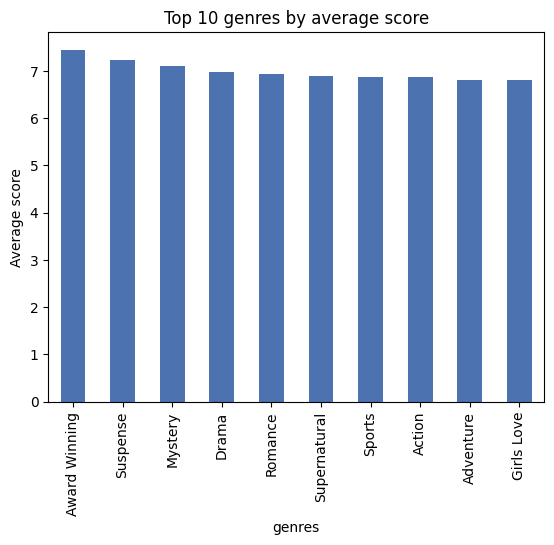

In [34]:
anime_genres = anime[anime['genres'] != 'Unknown'].copy()
anime_genres['genres'] = anime_genres['genres'].str.split(',')
anime_genres = anime_genres.explode('genres')
anime_genres['genres'] = anime_genres['genres'].str.strip()   # .title() removed: it turned 'Slice of Life' into 'Slice Of Life'
genres_score = (anime_genres.groupby('genres')['score'].mean().sort_values(ascending=False).head(10))

genres_score.plot(kind='bar', title='Top 10 genres by average score', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

**Finding:** the ten highest-scoring genres are *Award Winning*, *Suspense*, *Mystery*,
*Drama*, *Romance*, *Supernatural*, *Sports*, *Action*, *Adventure*, and *Girls Love*, with
average scores ranging from about 6.8 to 7.45. *Award Winning* stands out at the top (≈7.45), but
it is also one of the smallest genre groups in this list (209 titles), so its average is more
sensitive to a handful of highly-rated entries than genres like *Action* (4,124 titles) or
*Adventure* (2,799 titles). The gap across the rest of the top 10 is under one point, indicating
that once a genre is critically well-regarded, the differences between "top-tier" genres are
fairly small.

### 6.5 Genre Frequency and Genre Scores with a Minimum Sample Size

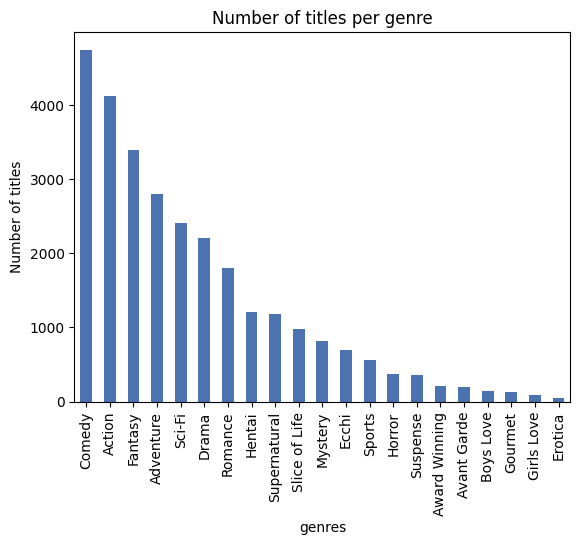

Largest genres: {'Comedy': 4749, 'Action': 4124, 'Fantasy': 3396, 'Adventure': 2799}


In [35]:
genre_stats = anime_genres.groupby('genres').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_favorites=('favorites', 'median'),
).round(2)

# Most frequent genres
genre_stats['titles'].sort_values(ascending=False).plot(kind='bar', title='Number of titles per genre', color='#4C72B0')
plt.ylabel("Number of titles")
plt.show()
print("Largest genres:", genre_stats['titles'].sort_values(ascending=False).head(4).to_dict())

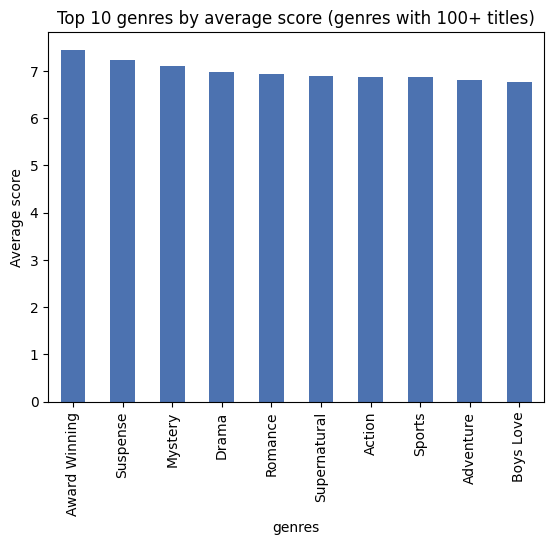

Genres with 100 or more titles: 19 of 21
Genres below the cut-off: {'Erotica': 47, 'Girls Love': 95}


,titles,avg_score,median_favorites
genres,,,
Award Winning,209,7.45,486.0
Suspense,361,7.23,341.0
Mystery,814,7.11,60.5
Drama,2211,6.97,39.0
Romance,1807,6.94,66.0
Supernatural,1181,6.89,39.0
Action,4124,6.88,34.0
Sports,560,6.88,16.0
Adventure,2799,6.81,15.0


In [36]:
# Only genres with at least 100 titles, so a handful of titles cannot decide the ranking
MIN_TITLES = 100
genre_100 = genre_stats[genre_stats['titles'] >= MIN_TITLES].sort_values('avg_score', ascending=False)

genre_100['avg_score'].head(10).plot(kind='bar', title='Top 10 genres by average score (genres with 100+ titles)', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

print("Genres with", MIN_TITLES, "or more titles:", len(genre_100), "of", len(genre_stats))
print("Genres below the cut-off:", genre_stats[genre_stats['titles'] < MIN_TITLES]['titles'].to_dict())
genre_100.head(10)

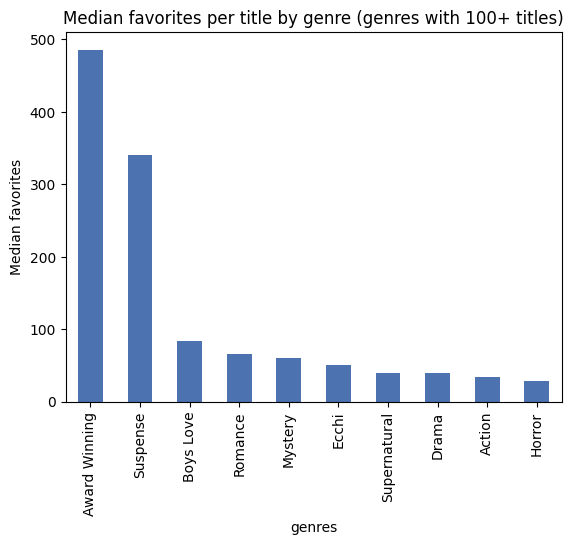

genres
Award Winning    486.0
Suspense         341.0
Boys Love         83.5
Romance           66.0
Mystery           60.5
Name: median_favorites, dtype: float64

In [37]:
# Do high-scoring genres also have high audience attachment?
genre_100['median_favorites'].sort_values(ascending=False).head(10).plot(kind='bar', title='Median favorites per title by genre (genres with 100+ titles)', color='#4C72B0')
plt.ylabel("Median favorites")
plt.show()
genre_100['median_favorites'].sort_values(ascending=False).head(5)

**Finding:** Comedy (4,749), Action (4,124), Fantasy (3,396) and Adventure (2,799) are the biggest genres. 19 of the 21
genres have at least 100 titles; *Girls Love* (95 titles) and *Erotica* (47) fall below the cut-off, which is why
*Girls Love* appears in the earlier top-10 chart but not in the 100+ chart. Among the genres with enough titles, *Award
Winning* (7.45), *Suspense* (7.23) and *Mystery* (7.11) have the highest average scores, and the lowest are
*Avant Garde* (6.25) and *Hentai* (6.40). The same two genres at the top, *Award Winning* and *Suspense*, also have by far
the highest median favorites (486 and 341, against 83.5 for the next genre). The spread between genres is small compared with
the spread between individual titles, so genre is a weak predictor of a single title's score.

### 6.6 Score Distribution

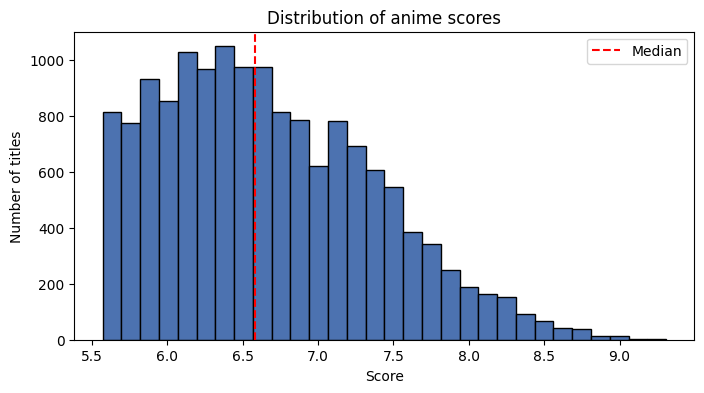

In [38]:
plt.figure(figsize=(8, 4))
plt.hist(anime['score'], bins=30, color='#4C72B0', edgecolor='black')
plt.axvline(anime['score'].median(), color='red', linestyle='--', label='Median')
plt.title('Distribution of anime scores')
plt.xlabel('Score')
plt.ylabel('Number of titles')
plt.legend()
plt.show()

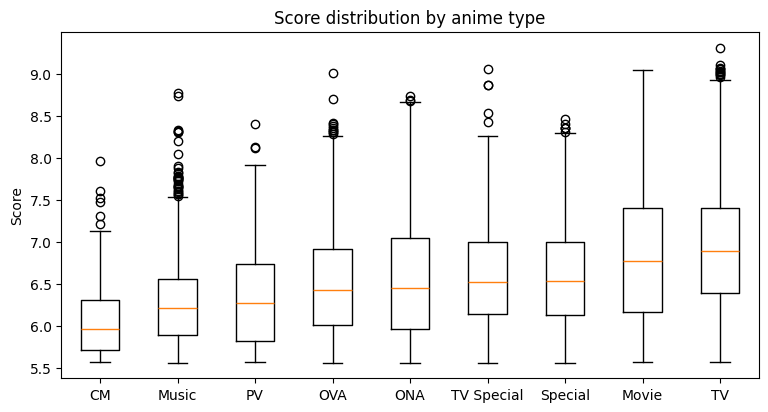

In [39]:
# Score spread for each type, ordered by median score
type_order = anime[anime['type'] != 'Unknown'].groupby('type')['score'].median().sort_values().index
plt.figure(figsize=(9, 4.5))
plt.boxplot([anime.loc[anime['type'] == t, 'score'] for t in type_order], tick_labels=type_order)
plt.title('Score distribution by anime type')
plt.ylabel('Score')
plt.show()

### 6.7 Popularity versus Rating

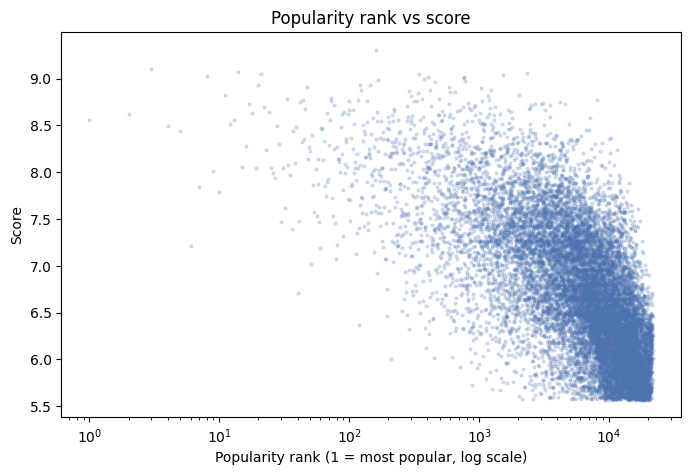

In [40]:
plt.figure(figsize=(8, 5))
plt.scatter(anime['popularity'], anime['score'], s=4, alpha=0.2, color='#4C72B0')
plt.xscale('log')
plt.title('Popularity rank vs score')
plt.xlabel('Popularity rank (1 = most popular, log scale)')
plt.ylabel('Score')
plt.show()

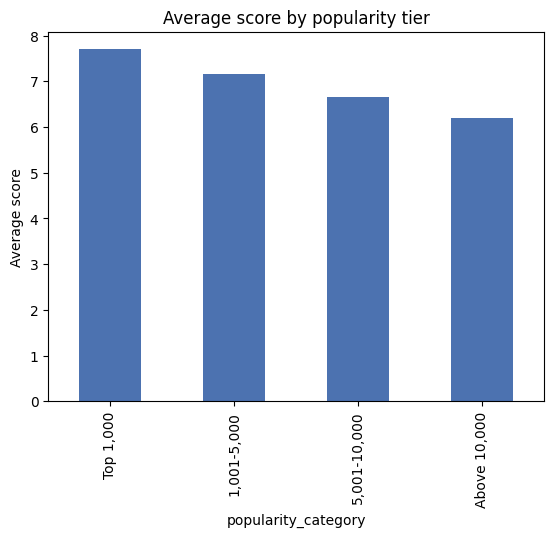

,titles,avg_score,median_score
popularity_category,,,
"Top 1,000",994,7.70,7.74
"1,001-5,000",3818,7.15,7.18
"5,001-10,000",4506,6.65,6.63
"Above 10,000",5647,6.19,6.12


In [41]:
pop_view = anime.groupby('popularity_category').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_score=('score', 'median'),
).round(2).reindex(pop_labels)

pop_view['avg_score'].plot(kind='bar', title='Average score by popularity tier', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

pop_view

**Finding:** better-rated titles are clearly more popular on average: the average score falls from 7.70 in the Top
1,000 tier to 7.15, 6.65 and 6.19 in the lower tiers. The scatter plot is wide, though, so the relationship is a
tendency and not a rule. Titles with few raters are rated mostly by a small group
of fans, so their score can be less stable.

### 6.8 Audience Engagement

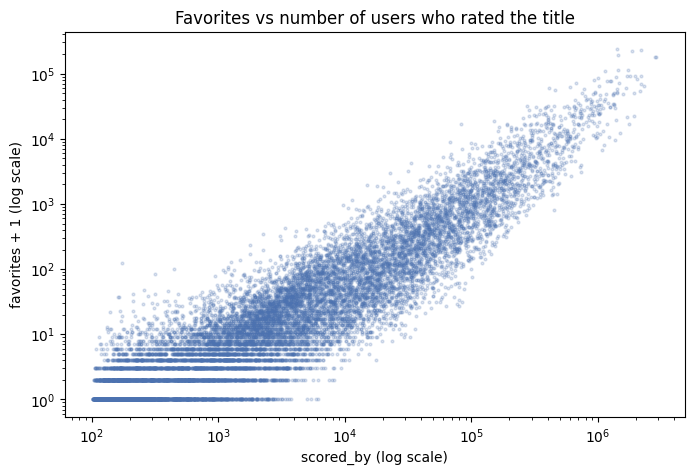

In [42]:
plt.figure(figsize=(8, 5))
plt.scatter(anime['scored_by'], anime['favorites'] + 1, s=4, alpha=0.2, color='#4C72B0')
plt.xscale('log')
plt.yscale('log')
plt.title('Favorites vs number of users who rated the title')
plt.xlabel('scored_by (log scale)')
plt.ylabel('favorites + 1 (log scale)')
plt.show()

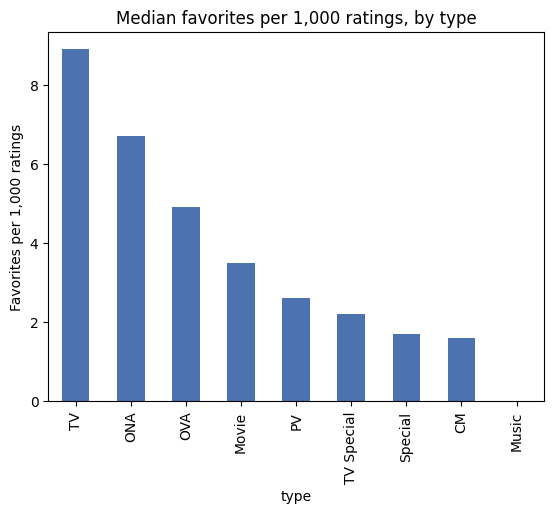

,titles,median_scored_by,median_favorites,median_favorites_per_1k
type,,,,
TV,4713,14831.0,124.0,8.9
ONA,1779,754.0,6.0,6.7
OVA,2778,2680.5,14.0,4.9
Movie,2084,2416.0,8.5,3.5
PV,128,435.0,1.5,2.6
TV Special,503,2437.0,4.0,2.2
Special,1295,2760.0,5.0,1.7
CM,206,547.0,1.0,1.6
Music,1478,266.0,0.0,0.0


In [43]:
# Engagement by type: how many favorites does a title get for every 1,000 users who rated it?
engagement = anime[anime['type'] != 'Unknown'].groupby('type').agg(
    titles=('anime_id', 'count'),
    median_scored_by=('scored_by', 'median'),
    median_favorites=('favorites', 'median'),
    median_favorites_per_1k=('favorites_per_1k_ratings', 'median'),
).round(1).sort_values('median_favorites_per_1k', ascending=False)

engagement['median_favorites_per_1k'].plot(kind='bar', title='Median favorites per 1,000 ratings, by type', color='#4C72B0')
plt.ylabel("Favorites per 1,000 ratings")
plt.show()

engagement

**Finding:** `favorites` grows with the number of raters, as expected, so I compare titles with favorites per 1,000
ratings. By that measure TV leads (median 8.9), followed by ONA (6.7), OVA (4.9) and Movie (3.5). In raw numbers the
difference is much bigger: the median TV series has 124 favorites, while no other type has a median above 14, and half
of the Music titles have no favorites at all. ONA is interesting because its audience is small (median 754 raters)
but relatively attached.

### 6.9 Studio Analysis

Studios in the data: 836
Studios with 30+ titles: 93


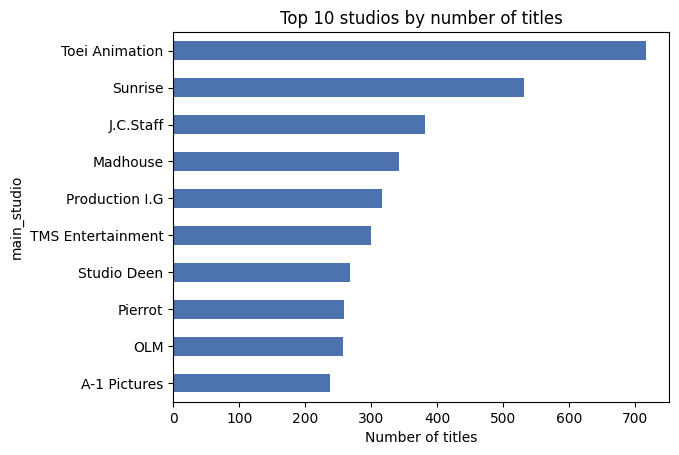

Most titles: {'Toei Animation': 716, 'Sunrise': 531, 'J.C.Staff': 382}


In [44]:
studio_stats = anime[anime['main_studio'] != 'Unknown'].groupby('main_studio').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    total_favorites=('favorites', 'sum'),
).round(2)

print("Studios in the data:", len(studio_stats))
print("Studios with 30+ titles:", (studio_stats['titles'] >= 30).sum())

studio_stats['titles'].sort_values(ascending=False).head(10).sort_values().plot(kind='barh', title='Top 10 studios by number of titles', color='#4C72B0')
plt.xlabel("Number of titles")
plt.show()
print("Most titles:", studio_stats['titles'].sort_values(ascending=False).head(3).to_dict())

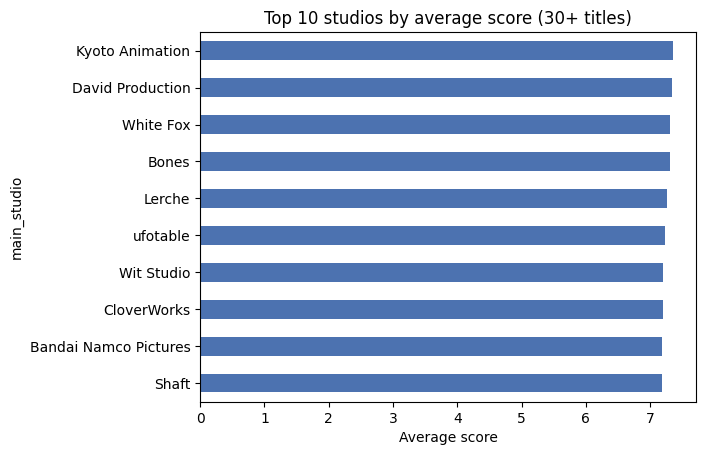

,titles,avg_score,total_favorites
main_studio,,,
Kyoto Animation,129,7.35,522698
David Production,45,7.34,198161
Bones,157,7.31,768938
White Fox,45,7.31,391025
Lerche,63,7.27,165093
ufotable,70,7.24,262706
CloverWorks,61,7.20,218583
Wit Studio,85,7.20,470759
Bandai Namco Pictures,56,7.19,39092


In [45]:
# Studios with at least 30 titles, ranked by average score
MIN_STUDIO_TITLES = 30
studio_30 = studio_stats[studio_stats['titles'] >= MIN_STUDIO_TITLES].sort_values('avg_score', ascending=False)

studio_30['avg_score'].head(10).sort_values().plot(kind='barh', title='Top 10 studios by average score (30+ titles)', color='#4C72B0')
plt.xlabel("Average score")
plt.show()

studio_30.head(10)

**Finding:** the studios with the most titles are Toei Animation (716), Sunrise (531) and J.C.Staff (382). Among the 93
studios with at least 30 titles, the highest average scores belong to Kyoto Animation (7.35), David Production (7.34)
and Bones (7.31). The top 10 are only 0.17 points apart, so I would not read the order too precisely. Making a lot of
titles does not mean a higher score: Toei Animation has the most titles but an average score of about 6.7, close to the
overall average. Titles from the same franchise count separately, which favors studios with sequels.

# 7. Statistical Analysis

### 7.1 Distribution Analysis

In [46]:
dist_cols = ['score', 'favorites', 'scored_by', 'episodes', 'duration_min']
dist_view = pd.DataFrame({
    'mean': anime[dist_cols].astype(float).mean(),
    'median': anime[dist_cols].astype(float).median(),
    'skewness': anime[dist_cols].astype(float).skew(),
}).round(2)
dist_view

,mean,median,skewness
score,6.67,6.58,0.55
favorites,805.11,11.00,21.01
scored_by,35946.48,2505.00,8.77
episodes,12.67,2.00,30.17
duration_min,25.55,23.00,2.04


**Finding:** only `score` is close to symmetric (skewness 0.55). `favorites` (21.0), `scored_by` (8.8) and `episodes`
(30.2) are extremely right-skewed, and `duration_min` is moderately skewed (2.0). In every skewed column the mean is far
above the median (for example 805 against 11 favorites), so a few huge titles pull the average up. That is why I use
**medians** and **Spearman** (rank) correlation below.

### 7.2 Correlation Analysis

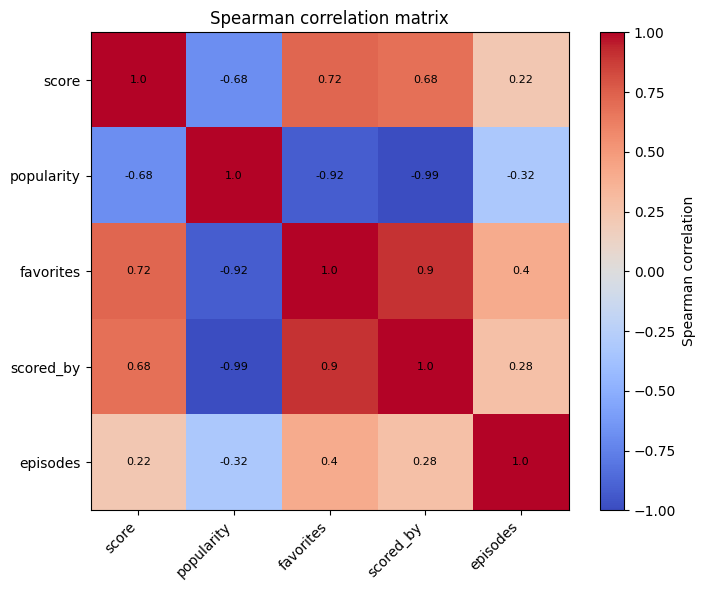

,score,popularity,favorites,scored_by,episodes
score,1.00,-0.68,0.72,0.68,0.22
popularity,-0.68,1.00,-0.92,-0.99,-0.32
favorites,0.72,-0.92,1.00,0.90,0.40
scored_by,0.68,-0.99,0.90,1.00,0.28
episodes,0.22,-0.32,0.40,0.28,1.00


In [47]:
# Spearman (rank) correlation: do two columns rise together? +1 = always, 0 = no link, -1 = one rises as the other falls.
# It is used instead of the normal correlation because favorites and scored_by are very skewed.
# 'rank' is left out on purpose: it is calculated from the score, so it would correlate almost perfectly by construction.
corr_cols = ['score', 'popularity', 'favorites', 'scored_by', 'episodes']
corr = anime[corr_cols].astype(float).corr(method='spearman').round(2)

plt.figure(figsize=(7.5, 6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Spearman correlation')
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha='right')
plt.yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, corr.iloc[i, j], ha='center', va='center', fontsize=8)
plt.title('Spearman correlation matrix')
plt.tight_layout()
plt.show()

corr

**Finding:** `score` is moderately to strongly related to audience size: `favorites` (0.72), `scored_by` (0.68) and
`popularity` (-0.68). `popularity` and `scored_by` are almost the same
measure (-0.99), so they carry the same information and I would not use both in one comparison. `favorites` and
`scored_by` are also strongly linked (0.90). `episodes` (0.22) has only a weak relationship with score. This shows
association only, not that more raters cause a higher score.

### 7.3 Comparing Groups

In [48]:
# Median score for each anime type (types with at least 100 titles, so a few titles cannot decide the result)
known = anime[anime['type'] != 'Unknown']
type_view = known.groupby('type')['score'].agg(['count', 'median']).round(2)
type_view = type_view[type_view['count'] >= 100].sort_values('median', ascending=False)
type_view

,count,median
type,,
TV,4713,6.89
Movie,2084,6.77
Special,1295,6.54
TV Special,503,6.53
ONA,1779,6.45
OVA,2778,6.43
PV,128,6.28
Music,1478,6.22
CM,206,5.96


In [49]:
# How much do TV and Movie overlap? Share of each type that scores above the overall median score
overall_median = anime['score'].median()
for t in ['TV', 'Movie']:
    share = (anime.loc[anime['type'] == t, 'score'] > overall_median).mean() * 100
    print("%-5s: %.1f%% of titles score above the overall median (%.2f)" % (t, share, overall_median))

TV   : 64.9% of titles score above the overall median (6.58)
Movie: 57.3% of titles score above the overall median (6.58)


**Finding:** TV has the highest median score (6.89), followed by Movie (6.77). CM (5.96) and Music (6.22) are the lowest.
The gap between TV and Movie is small: 64.9% of TV titles score above the overall median (6.58), against 57.3% of Movies,
so the two groups overlap a lot. I did not run significance tests. With about 15,000 rows even a tiny gap can look
"significant", so I look at the size of the gap and the overlap instead. Sequels from one franchise are also not
independent rows, which is another reason to read small differences carefully.

# 8. Analytical Insights

### 8.1 Popular does not always mean well rated (and the reverse)

In [50]:
top_pop = anime[anime['popularity_category'] == 'Top 1,000']
print("Titles in the 1,000 most popular tier:", len(top_pop))
print("...of which score below 7.0:", (top_pop['score'] < 7).sum())
print("...of which score 8.0 or more:", (top_pop['score'] >= 8).sum())
print()

# 'Hidden gems': high score, but outside the 5,000 most popular titles and rated by at least 1,000 users
gems = anime[(anime['score'] >= 7.8) & (anime['popularity'] > 5000) & (anime['scored_by'] >= 1000)]
print("Hidden gems found:", len(gems))
gems.sort_values('score', ascending=False)[['title', 'type', 'score', 'popularity', 'scored_by']].head(8)

Titles in the 1,000 most popular tier: 994
...of which score below 7.0: 144
...of which score 8.0 or more: 354

Hidden gems found: 82


,title,type,score,popularity,scored_by
37,Alien Stage,Music,8.77,8067,2275
110,Fights Break Sphere: Three Year Agreement,ONA,8.58,7118,4129
168,Uma Musume: Pretty Derby - Beginning of a New Era,Movie,8.45,6660,2990
172,Anime ID 51039,ONA,8.45,6957,3091
204,Ramayana: The Legend of Prince Rama,Movie,8.39,6077,6377
220,Swallowed Star 3rd Season,ONA,8.37,10415,1598
235,Swallowed Star 4th Season,ONA,8.35,9933,1204
237,Detective Conan Movie 26: Black Iron Submarine,Movie,8.35,5732,7253


**Finding:** being popular is not a guarantee of quality: 144 of the 994 titles in the most popular tier score below
7.0, although 354 score 8.0 or more. In the other direction, I found 82 "hidden gems" (score of at least 7.8, outside
the 5,000 most popular and rated by at least 1,000 users). This list is a rule-based shortlist and the thresholds are my
own choice, so it should be treated as a starting point for a closer look, not as a recommendation.

### 8.2 Does the number of episodes matter? (TV series only)

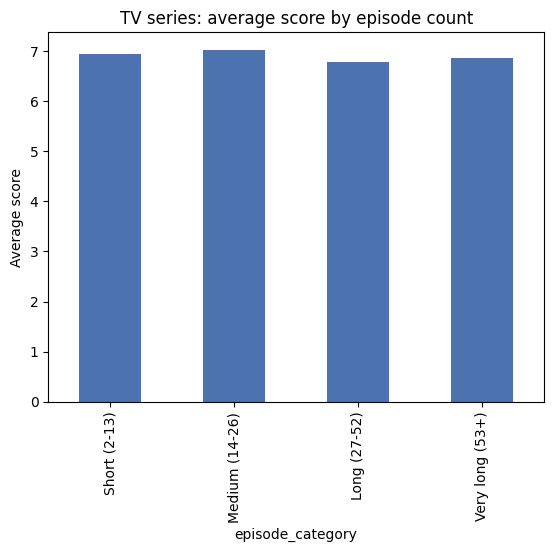

,titles,avg_score,median_favorites
episode_category,,,
Short (2-13),2509.0,6.95,272.0
Medium (14-26),1078.0,7.03,90.0
Long (27-52),787.0,6.78,14.0
Very long (53+),312.0,6.87,19.5
Unknown,27.0,6.69,27.0


In [51]:
tv = anime[anime['type'] == 'TV']
ep_view = tv.groupby('episode_category').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_favorites=('favorites', 'median'),
).round(2).reindex(ep_labels + ['Unknown']).dropna(how='all')   # no TV title has a single episode

ep_view[['avg_score']].drop('Unknown').plot(kind='bar', legend=False, title='TV series: average score by episode count', color='#4C72B0')
plt.ylabel("Average score")
plt.show()

ep_view

**Finding:** among TV series, medium-length shows (14-26 episodes) have the highest average score (7.03), followed by
short ones (6.95), very long ones (6.87) and long ones (6.78). There is no steady rise with length, and the gap between
the best and worst group is only about 0.25. The median favorites actually fall as the series gets longer (272 for short
series, 90 for medium, 14 for long and 19.5 for very long). The few huge long-running hits seen in 7.1 are the
exception and not the typical long series. I did not test why this happens.

### 8.3 Source material (TV series, at least 50 titles)

In [52]:
src_view = tv.groupby('source').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_favorites=('favorites', 'median'),
).round(2)
src_view = src_view[src_view['titles'] >= 50].sort_values('avg_score', ascending=False)
src_view

,titles,avg_score,median_favorites
source,,,
Manga,1693,7.20,272.0
Light novel,509,7.12,875.0
Web manga,169,7.10,418.0
Novel,147,7.07,53.0
4-koma manga,146,6.82,91.0
Visual novel,156,6.81,200.5
Original,1036,6.73,34.0
Mixed media,70,6.69,139.0
Game,270,6.64,57.0


**Finding:** adaptations of written works score higher than original anime: Manga (7.20), Light novel (7.12), Web manga
(7.10) and Novel (7.07), against Original (6.73) and Game (6.64). Titles with an unknown source score lowest (6.22, median
favorites 2). Light novels have the highest median favorites (875), ahead of Web manga (418) and Manga (272). Part of this
gap may be selection: studios tend to adapt stories that already have an audience, so the source may be a sign of that
and not the cause.

### 8.4 How concentrated is audience attachment?

In [53]:
total_fav = anime['favorites'].sum()
top10_share = anime.nlargest(10, 'favorites')['favorites'].sum() / total_fav * 100
n_top1pct = int(len(anime) * 0.01)
top1pct_share = anime.nlargest(n_top1pct, 'favorites')['favorites'].sum() / total_fav * 100
few_fav = (anime['favorites'] < 10).mean() * 100
tv_title_share = (anime['type'] == 'TV').mean() * 100
tv_fav_share = anime.loc[anime['type'] == 'TV', 'favorites'].sum() / total_fav * 100

print("Total favorites:", f"{total_fav:,}")
print("Share held by the top 10 titles: %.1f%%" % top10_share)
print("Share held by the top 1%% of titles (%d titles): %.1f%%" % (n_top1pct, top1pct_share))
print("Titles with fewer than 10 favorites: %.1f%%" % few_fav)
print("TV series are %.1f%% of all titles but hold %.1f%% of all favorites" % (tv_title_share, tv_fav_share))

Total favorites: 12,048,420
Share held by the top 10 titles: 13.8%
Share held by the top 1% of titles (149 titles): 55.8%
Titles with fewer than 10 favorites: 47.2%
TV series are 31.5% of all titles but hold 87.7% of all favorites


**Finding:** attachment is highly concentrated. The top 10 titles hold 13.8% of the 12.0 million favorites, the top 1%
(149 titles) hold 55.8%, and 47.2% of titles have fewer than 10 favorites. TV series are 31.5% of the titles but hold
87.7% of all favorites. A catalogue's favorites are therefore driven by a small number of hits.

### 8.5 Has the average score of TV series changed over time?

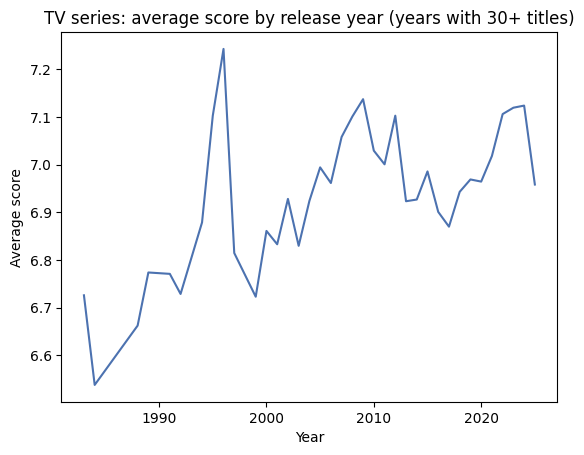

year
1983    6.73
1992    6.73
1998    6.77
2003    6.83
2008    7.10
2013    6.92
2018    6.94
2023    7.12
Name: mean, dtype: float64

In [54]:
tv_year = tv.groupby('year')['score'].agg(['mean', 'count'])
tv_year = tv_year[tv_year['count'] >= 30]

tv_year['mean'].plot(kind='line', title='TV series: average score by release year (years with 30+ titles)', color='#4C72B0')
plt.xlabel('Year')
plt.ylabel('Average score')
plt.show()

tv_year['mean'].round(2).iloc[::5]

**Finding:** the average score of TV series stays in a narrow band of roughly 6.7 to 7.1 across the years shown
(only every fifth qualifying year is printed). It is a little higher in the 2008 and 2023 rows than in the 1980s and
1990s, but the line moves up and down, so I would not call it a trend. Older titles in a top-by-score list are
the ones that are still remembered and rated, so the older years are probably flattered.

### 8.6 Age rating

In [55]:
age_view = anime.groupby('Age_can_read').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_favorites=('favorites', 'median'),
).round(2).sort_values('avg_score', ascending=False)
age_view

,titles,avg_score,median_favorites
Age_can_read,,,
R - 17+ (violence & profanity),1302,7.11,123.0
PG-13 - Teens 13 or older,7499,6.83,20.0
R+ - Mild Nudity,843,6.61,34.0
PG - Children,938,6.50,4.0
Rx - Hentai,1205,6.40,20.0
G - All Ages,3110,6.30,1.0
Unknown,68,6.25,2.0


In [56]:
# Is the age pattern just a format effect? Type mix of the 'G - All Ages' titles, then the same table for TV series only
print((anime.loc[anime['Age_can_read'] == 'G - All Ages', 'type'].value_counts(normalize=True).head(3) * 100).round(1).to_dict())
print()
tv.groupby('Age_can_read').agg(
    titles=('anime_id', 'count'),
    avg_score=('score', 'mean'),
    median_favorites=('favorites', 'median'),
).round(2).sort_values('avg_score', ascending=False)

{'Music': 25.5, 'TV': 22.2, 'Movie': 19.4}



,titles,avg_score,median_favorites
Age_can_read,,,
R - 17+ (violence & profanity),566,7.36,993.0
PG-13 - Teens 13 or older,2770,7.02,208.5
R+ - Mild Nudity,261,6.74,227.0
G - All Ages,691,6.57,6.0
PG - Children,393,6.53,8.0
Unknown,32,6.23,2.5


**Finding:** *R - 17+* has the highest average score (7.11) and *G - All Ages* the lowest apart from the unknown group
(6.30, median favorites of 1). This is partly a format effect: more than half of the G titles are Music, TV or Movie
(25.5%, 22.2% and 19.4%), and Music scores low. Within TV series only the gap remains (R - 17+ 7.36 against G 6.57,
and median favorites of 993 against 6). So titles aimed at older audiences do better on both signals in this data.

### 8.7 Key Findings

- `premiered` is empty for 69% of titles, but this is structural: only TV series have it. Release-year analysis is
  therefore TV-only. Other gaps (`english_name`, `rank`, `producers`) do not affect the main analysis.
- All ten of the most-favorited titles are TV series, led by *One Piece*, *Fullmetal Alchemist: Brotherhood* and
  *Hunter x Hunter*. Only four of the ten have more than 30 episodes (one more has no episode count).
- **TV** (median 6.89) and **Movie** (6.77) have the highest scores. This corrects an inaccurate claim in the original
  analysis that Movie scored highest. The difference between them is small (64.9% of TV titles and 57.3% of Movies
  score above the overall median) and short formats (CM, Music, PV) score lowest.
- Better-rated titles tend to be more popular (Spearman 0.72 with favorites, average score 7.70 in the Top 1,000 tier
  against 6.19 in the lowest), but there are exceptions in both directions.
- *Award Winning*, *Suspense* and *Mystery* are the highest-scoring genres, with *Award Winning* (209 titles) and
  *Suspense* (361) also having the highest median favorites. Genre differences are small compared with the
  differences between titles.
- Favorites are very concentrated: 1% of the titles hold 55.8% of them, and TV series hold 87.7%.
- Adaptations (Manga, Light novel) score higher than original titles, and R-rated TV series score higher and have more
  favorites than children's ratings.

# Recommendations

These recommendations follow from the findings above. They are suggestions to test, not guarantees, because the data
is a snapshot of a top-rated list and the analysis is descriptive.

1. **Prioritise TV series when the goal is audience attachment.** TV series hold 87.7% of all favorites, have the
   highest median favorites (124) and the highest favorites per 1,000 ratings (8.9). Length is not the key: series of 14-26
   episodes score best (7.03).
2. **Look at manga and light novel adaptations first.** They score about 0.4-0.5 points above original titles (7.20
   and 7.12 against 6.73), and light novels have the highest median favorites (875).
3. **Use genre as a secondary filter.** *Mystery*, *Suspense* and *Award Winning* rank highest, but the gaps are
   small, so a good title in any genre matters more than the genre itself.
4. **Do not judge by popularity alone.** 144 of the 994 most popular titles score below 7.0, while 82 titles meet the
   hidden-gem rule. The shortlist is a good place to start a licensing review.
5. **Plan for a hit-driven catalogue.** Since 1% of titles hold 55.8% of the favorites, marketing effort is best focused
   on the few titles with real fan attachment.
6. **Treat studio rankings carefully.** The best studios are close together (7.35 to 7.18), so use them as a tie-breaker
   and not as a reason to choose a title.

# Limitations

- **Selection bias.** The file seems to be a "top 15,000 by score" list (the lowest score is 5.57), so poorly rated
  titles are missing. Differences between "good" and "bad" titles are probably understated, and correlations with score
  are weakened.
- **TV-only release dates.** `premiered` exists for TV series only, so the year analysis says nothing about movies,
  OVAs or ONAs.
- **No member count.** I use `scored_by` as the audience size, but it only counts users who rated the title.
- **Non-independence.** Sequels and seasons of one franchise are separate rows, so franchises with many entries have
  extra weight in averages and the rows are not truly independent.
- **Duplicates and missing values.** 35 exact duplicates were removed. Missing `episodes`, `rank` and
  `english_name` were left as they are, and 'Unknown' was used as a label for category columns.
- **Snapshot.** Scores and favorites change over time, and 2025 is a partial year.
- **Descriptive only.** The results show associations (for example between source and score), not causes, and the
  popularity tiers and hidden-gem thresholds are my own choices.